<a href="https://colab.research.google.com/github/suganthavk-ai/Bank-Marketing-Campaign-Analysis/blob/main/Bank_Marketing_Campaign_Analysis_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

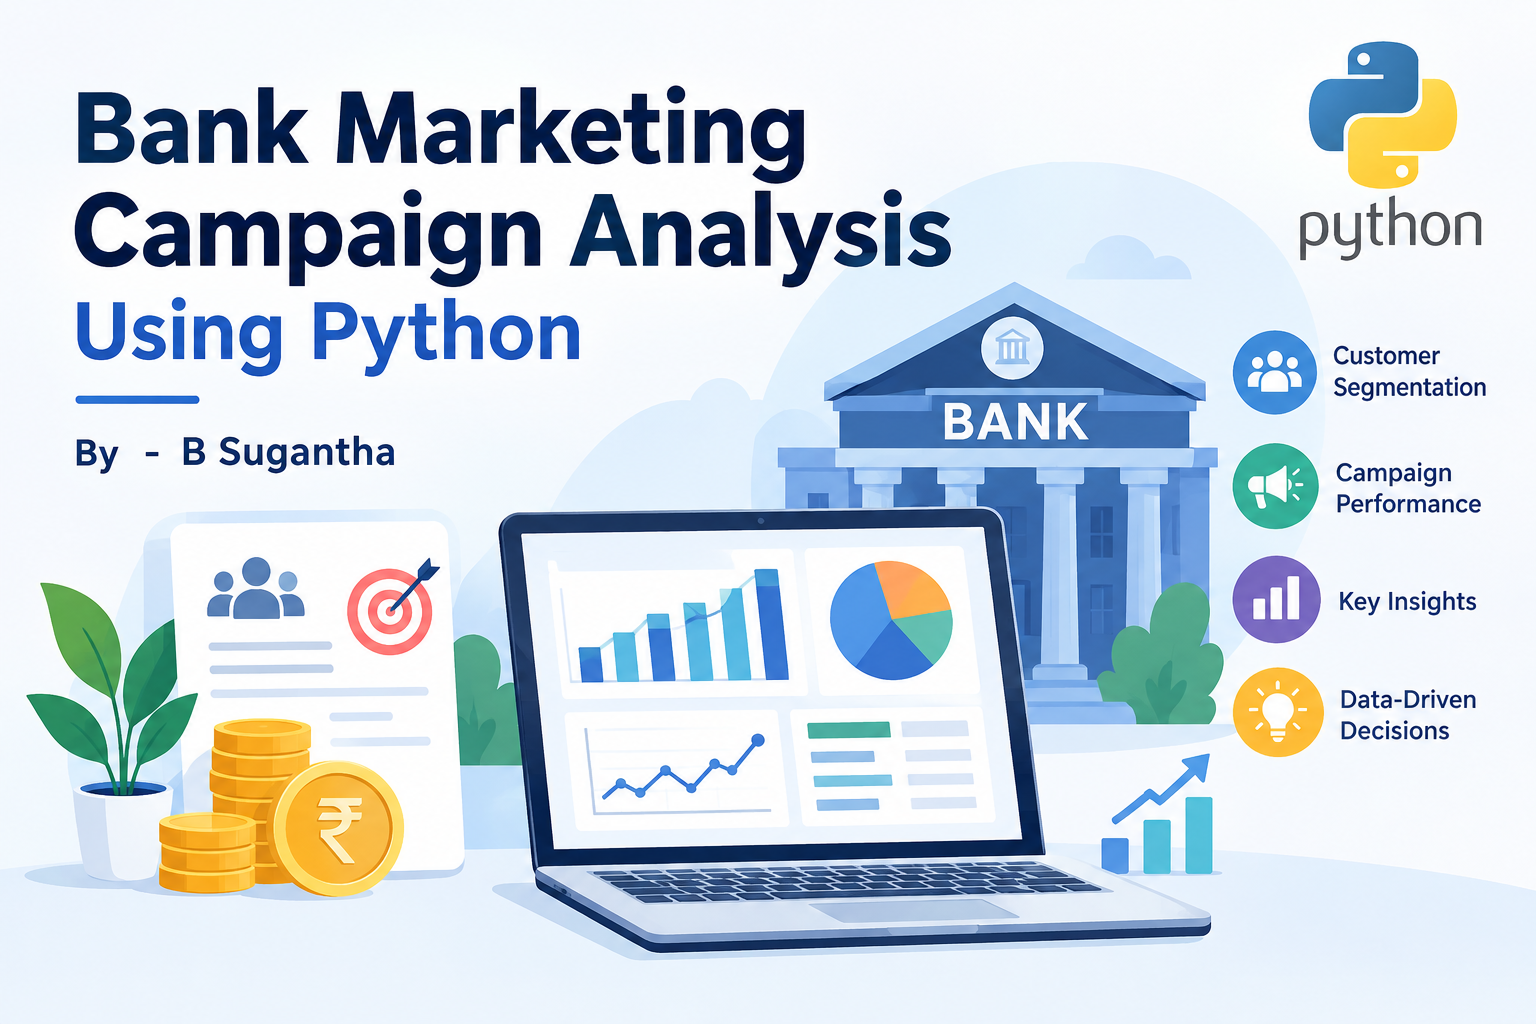

# **Project Title - Bank Marketing Campaign Analysis**

# **Objective**
1. Was the bank marketing campaign successful?

2. Which month had the highest subscription rate?

3. Which contact method was most successful?

4. Does contacting customers multiple times improve subscription rates?

5. Which age group responds best to the campaign?

6. Does call duration affect subscription success?

7. Were customers contacted in previous campaigns more likely to subscribe?

8. Which previous campaign outcome leads to higher subscriptions?

9. Age vs Account Balance by Subscription

10. Which Job Category Has the Highest Subscription Rate?


# **Outcome**
Analyze customer demographics, financial characteristics, and marketing campaign performance to understand the factors associated with customers subscribing to bank term deposits.

# **Domain**
1. Title: Bank Marketing  
2. Sources
   Created by: Paulo Cortez (Univ. Minho) and Sérgio Moro (ISCTE-IUL) @ 2012



# **Dataset information**

**Source:** UCI ML Repository

**Link:** https://archive.ics.uci.edu/dataset/222/bank+marketing

**Year / Timeline:** Data collected during 2008 to 2013

**Dataset Column/features Description:**
A data mining approach to predict the success of telemarketing calls for selling bank long-term deposits in Portuguese retail bank was addressed, with data collected from 2008 to 2013, thus including the effects of the recent financial crisis.
Expand

# Bank Client Data:
* **Age** – Customer age

* **Job** – Type of job

* **Marital** – Marital status

* **Education** – Education level

* **Balance** – Average yearly balance

* **Housing** – Housing loan status

* **Loan** – Personal loan status

* **Contact** – Communication method

* **Month** – Contact month

* **Duration** – Last contact duration

* **Campaign** – Number of contacts during the current campaign

* **Pdays** – Days since previous campaign contact

* **Previous** – Number of contacts before the current campaign

* **Poutcome** – Outcome of the previous campaign

* **y** – Current campaign subscription outcome

# **Data Cleaning & Pre-processing**

In [1]:
# import library

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns


**Result explanation:** These libraries provide the tools required to clean the Bank Marketing dataset, perform calculations, analyse customer behaviour and create visualisations.

In [2]:
import pandas as pd

url = "https://raw.githubusercontent.com/suganthavk-ai/Bank-Marketing-Campaign-Analysis/refs/heads/main/Bank%20Marketing%20Campaign%20Analysis.xlsx"

df = pd.read_excel(url)

df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


**Result explanation:** The dataset was successfully loaded, and the first five customer records were displayed. The records include customer demographics, financial information, campaign contact details and the subscription outcome.

In [3]:
df.tail()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
45206,51,technician,married,tertiary,no,825,no,no,cellular,17,nov,977,3,-1,0,unknown,yes
45207,71,retired,divorced,primary,no,1729,no,no,cellular,17,nov,456,2,-1,0,unknown,yes
45208,72,retired,married,secondary,no,5715,no,no,cellular,17,nov,1127,5,184,3,success,yes
45209,57,blue-collar,married,secondary,no,668,no,no,telephone,17,nov,508,4,-1,0,unknown,no
45210,37,entrepreneur,married,secondary,no,2971,no,no,cellular,17,nov,361,2,188,11,other,no


**Result explanation:** The last five records were displayed, with row indexes from 45206 to 45210. The dataset contains customer records through index 45210, which is consistent with 45,211 records when indexing starts at zero.

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


**Result explanation:**

Total entries: 45,211



Total columns: 17



Numerical columns: 7 (int64)



Categorical/text columns: 10 (object)



Non-null values: 45,211 in every column

All 45,211 rows have non-null values in all 17 columns. This suggests that there are no standard null or missing values in the dataset. However, text values such as "unknown" must be checked separately because Pandas does not automatically treat them as missing values.

In [5]:
# Number of rows and columns
print("Shape:",df.shape)

Shape: (45211, 17)


**Result Explaination:**

df.shape returns a tuple containing the number of rows and columns. The dataset contains 45,211 rows and 17 columns. Each row represents a customer record, and the columns contain customer attributes and campaign information.
This confirms that the dataset has sufficient records for detailed exploratory data analysis.

In [6]:
# Column Names
print("\nColumns:")
print(df.columns.tolist())


Columns:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']


**Result Explanation:**
- "\nColumns:" prints a heading on a new line. \n represents a newline character.
- df.columns retrieves the column names.
- .tolist() converts the column index into a regular Python list.

- All 17 column names were identified. The columns cover demographic details, account balance, loan information, contact history and the campaign's final subscription outcome.

In [7]:
# Column Types
print("\nData Type:")
print(df.dtypes)


Data Type:
age           int64
job          object
marital      object
education    object
default      object
balance       int64
housing      object
loan         object
contact      object
day           int64
month        object
duration      int64
campaign      int64
pdays         int64
previous      int64
poutcome     object
y            object
dtype: object


**Result Explaination:**

- **Integer-valued numerical data(int64):**	age, balance, day, duration, campaign, pdays, previous

- **Text or categorical data(Object):** job, marital, education, default, housing, loan, contact, month, poutcome, y

- df.dtypes returns the data type of each column.

- int64 represents integer-valued data.

- Object commonly represents text or categorical values in Pandas.

 The columns have data types suitable for the initial analysis.

 - Numerical columns can be used for statistical calculations,

 - While categorical columns can be used to analyse customer groups and subscription outcomes.

- No data type conversion is required at this initial stage based on the displayed output.

In [8]:
# Basic statistical summary
df.describe()


,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


**Result Explanation:**
df.describe() calculates summary statistics for numerical columns by default.
- count: Number of non-null observations.
- mean: Average value.
- std: Standard deviation, indicating how spread out the values are.
- min: Minimum value.
- 25%: First quartile.
- 50%: Median.
- 75%: Third quartile.
- max: Maximum value.

- The ***average customer*** age is approximately ***41 years***, the ***average account balance is 1,362.27***, and the ***average call duration*** is about ***258 seconds***.

- The large differences between the median and maximum values for ***balance and duration*** suggest that these variables may contain extreme values and could be ***right-skewed.***


In [9]:
# Check missing values
df.isnull().sum()

,0
age,0
job,0
marital,0
education,0
default,0
balance,0
housing,0
loan,0
contact,0
day,0


**Result Explaination:**

- All 17 columns returned 0.

- df.isnull() checks each cell for a standard missing value, such as NaN.
- .sum() counts the missing values column by column.
- No standard null values were found in any column. Therefore, there is no immediate need to impute or remove records because of standard missing values.
- The text value **"unknown"** is not the same as a null value. It needs a separate check.

In [10]:
# Count unknown values
for col in df.select_dtypes(include="object").columns:
    count = (df[col] == "unknown").sum()
    if count > 0:
        print(col, ":", count)

job : 288
education : 1857
contact : 13020
poutcome : 36959


**Result Explaination:**
- The job, education, contact and poutcome columns contain unknown values. The largest count is in poutcome, with 36,959 records.
- These values are being retained as a separate category instead of automatically being treated as missing data.
- This allows you to investigate whether unavailable information is associated with campaign outcomes.

In [11]:
# Duplicate records
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


**Result Explaination:**
- No fully duplicated records were identified. Therefore, no rows were removed during duplicate handling.
- This checks for identical rows, not whether the same customer appears multiple times under different records.

In [12]:
# rename y to subscription:
df.rename(columns={"y": "subscription"}, inplace=True)
df["subscription"].value_counts()

,count
subscription,
no,39922
yes,5289


**Result Explanation:**
- df.rename() renames a column.
- columns={"y": "subscription"} specifies the old and new column names.
- inplace=True modifies the existing DataFrame directly.
- df["subscription"] selects the renamed column.
- .value_counts() counts the occurrences of each distinct value.
Result interpretation: Out of 45,211 records, 39,922 customers did not subscribe to the term deposit, while 5,289 customers subscribed.
- The subscription rate is approximately 11.70%, while the non-subscription rate is approximately 88.30%. This indicates that the dataset contains substantially more non-subscribing customers than subscribing customers.
- Renaming y to subscription makes the target column easier to understand in subsequent analysis.

In [13]:
# Data types

# Numerical columns
numeric_columns = df.select_dtypes(include=np.number).columns
print("Numerical columns:")
print(numeric_columns)

Numerical columns:
Index(['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous'], dtype='object')


**Result Explanation:**
- include=np.number selects columns containing numerical data types.
- .columns retrieves their names.
- numeric_columns stores the selected column names in a variable.
- print() displays the result.
- Seven numerical columns were identified. These variables can be used for statistical summaries, outlier detection, distributions and numerical comparisons.

In [14]:
# Categorical columns
categorical_columns = df.select_dtypes(include="object").columns
print("\nCategorical columns:")
print(categorical_columns)


Categorical columns:
Index(['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact',
       'month', 'poutcome', 'subscription'],
      dtype='object')


**Result Explanation:**
- This code selects columns with the object data type and stores their names in categorical_columns.
- The categorical columns represent customer characteristics, financial product indicators, contact details, campaign outcomes and the subscription target.
- They are useful for comparing subscription rates across customer groups.

In [15]:
#Skewness and kurtosis
pd.DataFrame({
    'skewness': df.select_dtypes(include='number').skew(),
    'kurtosis': df.select_dtypes(include='number').kurt()
}).round(2)

,skewness,kurtosis
age,0.68,0.32
balance,8.36,140.75
day,0.09,-1.06
duration,3.14,18.15
campaign,4.90,39.25
pdays,2.62,6.94
previous,41.85,4506.86


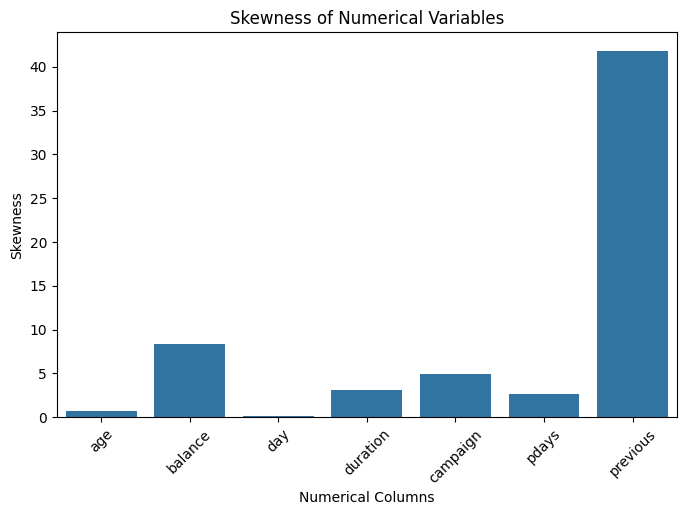

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

skewness = df.select_dtypes(include='number').skew()

plt.figure(figsize=(8, 5))

sns.barplot(x=skewness.index, y=skewness.values)

plt.title("Skewness of Numerical Variables")
plt.xlabel("Numerical Columns")
plt.ylabel("Skewness")
plt.xticks(rotation=45)
plt.show()

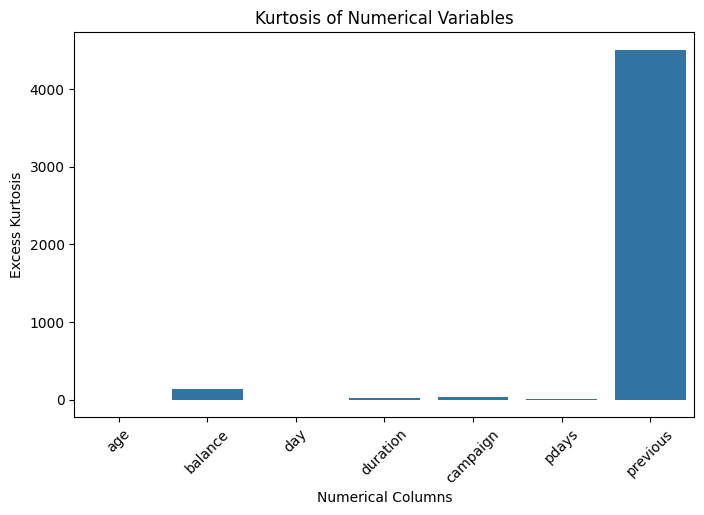

In [17]:
kurtosis = df.select_dtypes(include='number').kurt()

plt.figure(figsize=(8, 5))

sns.barplot(x=kurtosis.index, y=kurtosis.values)

plt.title("Kurtosis of Numerical Variables")
plt.xlabel("Numerical Columns")
plt.ylabel("Excess Kurtosis")
plt.xticks(rotation=45)
plt.show()

In [18]:
numeric_cols = df.select_dtypes(include='number').columns

for col in numeric_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    count = ((df[col] < lower) | (df[col] > upper)).sum()
    print(f"{col}: {count} outliers")

age: 487 outliers
balance: 4729 outliers
day: 0 outliers
duration: 3235 outliers
campaign: 3064 outliers
pdays: 8257 outliers
previous: 8257 outliers


**Syntax Explanation:**
1. select_dtypes(include='number') selects all numerical columns from the dataset.
2. quantile(0.25) and quantile(0.75) calculate Q1 and Q3, while iqr = q3 - q1 calculates the Interquartile Range.
3. The code identifies values below Q1 - 1.5 × IQR or above Q3 + 1.5 × IQR and prints the number of outliers in each column.

**Result Explanation:**
1. The output displays the number of outliers present in each numerical column.
2. Outliers are values that fall outside the calculated lower and upper limits.
3. Columns with higher outlier counts may contain more unusual or extreme values.

**Project Conclusion:**
1. Outlier detection helps identify unusual values in numerical features such as age, balance, duration, and campaign.
2. Identifying outliers improves understanding of data distribution and potential data quality issues.
3. Outliers should be investigated before removal because some extreme values may represent genuine customer information.
Overall Conclusion: The IQR method helps detect unusual numerical values and supports better data preprocessing for bank marketing analysis.

# **EDA & Visualizations**

**Chart 1:** Overall campaign success — Donut chart

**1. Was the bank marketing campaign successful?**



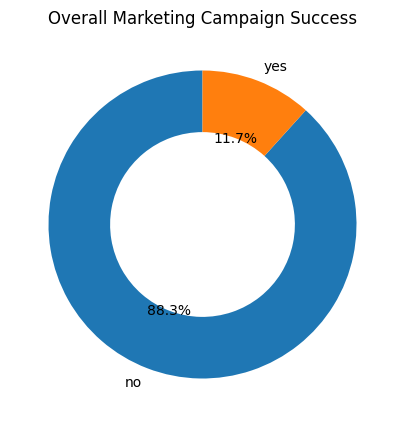

In [19]:
plt.figure(figsize=(8, 5))

plt.pie(df["subscription"].value_counts(),
        labels=df["subscription"].value_counts().index,
        autopct="%1.1f%%",
        startangle=90,
        wedgeprops={"width": 0.4})

plt.title("Overall Marketing Campaign Success")
plt.show()

**Syntax Explanation:**

1. plt.figure(figsize=(8, 5)) – Sets the chart size.
2. plt.pie() – Creates a pie chart.
3. value_counts() – Counts customers in each subscription category.
4. labels – Displays Yes and No categories.
5. autopct – Shows percentages with one decimal place.
6. startangle=90 – Starts the chart at 90 degrees.
7. wedgeprops – Creates the donut shape.
8. plt.title() – Adds the chart title.
9. plt.show() – Displays the chart.

**Result Explanation:**
1. The donut chart shows the percentage of customers who subscribed and did not subscribe.
2. The larger segment represents the higher percentage.
3. It helps understand the overall campaign success rate.

**Project Conclusion:**
The chart helps the bank evaluate its marketing campaign performance and identify opportunities to improve customer subscriptions.

**Chart 2:** Best-performing month — Line chart

**2. Which month had the highest subscription rate?**

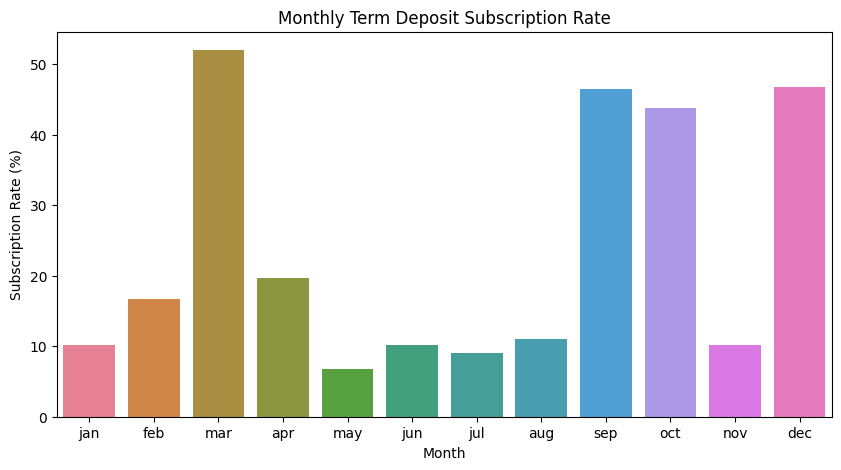

In [23]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Step 1: Create subscribed column
# Convert yes = 1 and no = 0
if "subscription" in df.columns:
    df["subscribed"] = df["subscription"].astype(str).str.lower().eq("yes").astype(int)
else:
    df["subscribed"] = df["y"].astype(str).str.lower().eq("yes").astype(int)

# Step 2: Calculate monthly subscription rate
month_rate = df.groupby("month", observed=True)["subscribed"].mean() * 100

# Step 3: Arrange months in chronological order
month_order = ["jan", "feb", "mar", "apr", "may", "jun",
               "jul", "aug", "sep", "oct", "nov", "dec"]

month_rate = month_rate.reindex(month_order).dropna()

# Step 4: Create bar chart
plt.figure(figsize=(10, 5))

sns.barplot(
    x=month_rate.index,
    y=month_rate.values,
    hue=month_rate.index,
    palette="husl",
    legend=False
)

plt.title("Monthly Term Deposit Subscription Rate")
plt.xlabel("Month")
plt.ylabel("Subscription Rate (%)")
plt.show()


**Syntax Explanation:**
1. df["subscribed"] – Creates a new column where yes = 1 and no = 0.
2. groupby("month") – Groups customers based on the contact month.
3. mean() * 100 – Calculates the percentage of customers who subscribed each month.
4. reindex(month_order) – Arranges the months from January to December.
5. sns.barplot() – Displays the monthly subscription rates using different colors.

**Result Explanation:**
1. The X-axis represents the months.
2. The Y-axis represents the term deposit subscription rate (%).
3. Taller bars indicate months with higher subscription rates.
4. Shorter bars indicate months with lower subscription rates.

**Project Conclusion:**
The monthly subscription rate analysis helps identify which months have higher customer conversion rates. Banks can use these insights to investigate seasonal patterns and improve campaign planning.

**Important:** A higher monthly subscription rate does not necessarily mean more subscriptions overall. Also compare the number of customers contacted each month before deciding which months performed best.

**Chart 3:** Best contact method — Colourful horizontal bar chart

**Which contact method was most successful?**

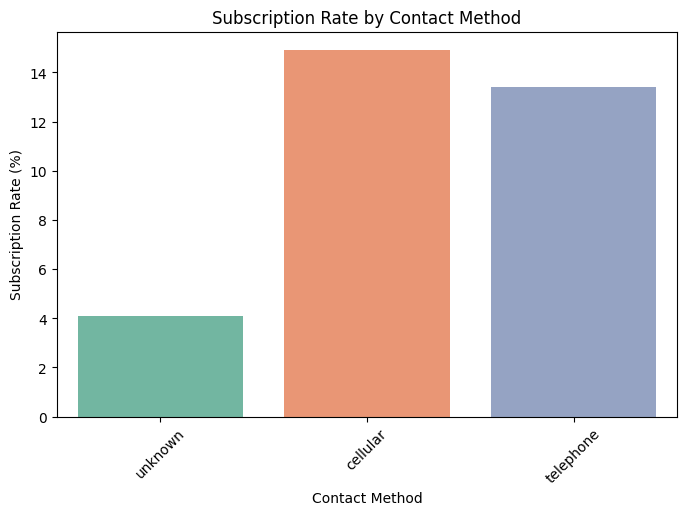

In [24]:
df["subscribed"] = (df["subscription"] == "yes").astype(int) * 100

plt.figure(figsize=(8, 5))

sns.barplot(data=df, x="contact", y="subscribed",
            hue="contact", palette="Set2",
            estimator="mean", errorbar=None, legend=False)

plt.title("Subscription Rate by Contact Method")
plt.xlabel("Contact Method")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation=45)
plt.show()

**Syntax Explaination:**
1. df.groupby("contact") – Groups customers based on their contact method (cellular, telephone, etc.).

2. ["subscription"] – Selects the subscription column.

3. lambda x: – Creates a small function to calculate the subscription rate.

4. (x == "yes") – Checks whether each customer subscribed.

5 .mean() – Calculates the proportion of customers who subscribed.

6. 100 – Converts the proportion into a percentage.

7. .sort_values(ascending=False) – Arranges subscription rates from highest to lowest.

**Result Explanation:**
1. The X-axis represents different contact methods, such as cellular, telephone, and unknown.
2. The Y-axis represents the subscription rate in percentage.
3. Each bar shows the percentage of customers who subscribed through a particular contact method.
4. Taller bars indicate higher subscription rates.
5. The chart helps identify which contact method is associated with better subscription outcomes.

**Project Conclusion:**
This analysis helps the bank identify contact methods associated with higher term deposit subscription rates. These insights can support improvements in communication strategies and customer targeting.

**Chart 4:** Area chart — explores how subscription rates change with contact frequency.

**Does contacting customers multiple times improve subscription rates?**

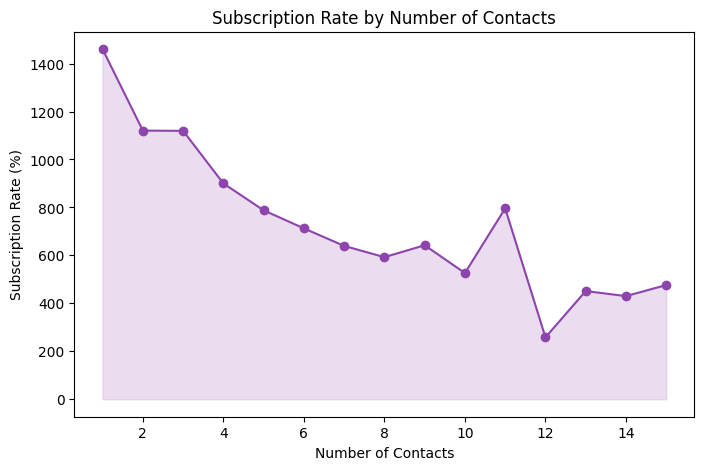

In [25]:
campaign_rate = df.groupby("campaign")["subscribed"].mean() * 100

campaign_rate = campaign_rate.head(15)

plt.figure(figsize=(8, 5))

plt.fill_between(campaign_rate.index, campaign_rate.values,
                 color="#D7BDE2", alpha=0.5)

plt.plot(campaign_rate.index, campaign_rate.values,
         color="#8E44AD", marker="o")

plt.title("Subscription Rate by Number of Contacts")
plt.xlabel("Number of Contacts")
plt.ylabel("Subscription Rate (%)")
plt.show()

Syntax Explanation
1. df.groupby("campaign") – Groups customers based on the number of contacts.
2. ["subscribed"].mean() – Calculates the average subscription value.
3. * 100 – Converts the subscription rate into a percentage.
4. .head(15) – Selects the first 15 contact-count categories.
5. plt.figure(figsize=(8, 5)) – Sets the chart size.
6. plt.fill_between() – Creates the shaded area chart.
7. color="#D7BDE2" – Sets the area color to light purple.
8. alpha=0.5 – Makes the shaded area transparent.
9. plt.plot() – Draws a line showing the subscription trend.
10. marker="o" – Displays circular markers on the line.
11. plt.title(), plt.xlabel(), plt.ylabel() – Add chart title and labels.
12. plt.show() – Displays the chart.

**Result Explanation**
1. The area chart shows how subscription rates change with the number of campaign contacts.
2. The X-axis represents the number of times customers were contacted.
3. The Y-axis represents the subscription rate in percentage.
4. An upward trend indicates higher subscription rates at higher contact counts.
5. A downward trend indicates lower subscription rates at higher contact counts.

**Project Conclusion**
This analysis helps the bank understand the relationship between contact frequency and term deposit subscriptions.

It can help identify contact frequencies associated with higher subscription rates and support more effective marketing strategies.

Important: This analysis shows an association, not proof that making more calls improves subscriptions.

**Chart 5**

Which age group responds best to the campaign?

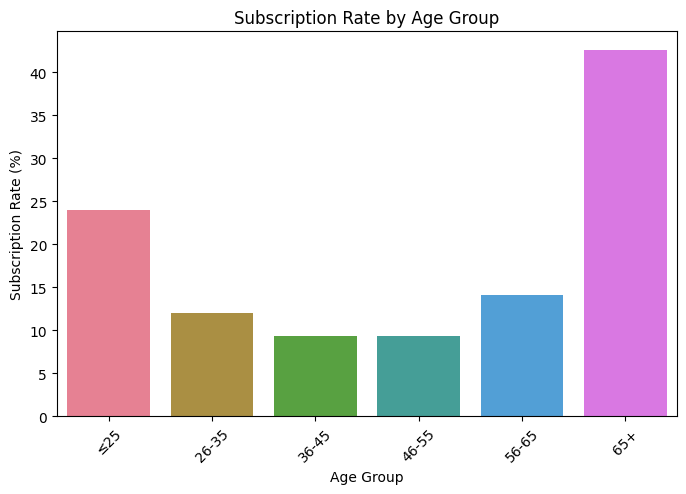

In [26]:
df["age_group"] = pd.cut(df["age"],
                         bins=[0, 25, 35, 45, 55, 65, float("inf")],
                         labels=["≤25", "26-35", "36-45",
                                 "46-55", "56-65", "65+"])

df["subscribed"] = (df["subscription"] == "yes").astype(int) * 100

plt.figure(figsize=(8, 5))

sns.barplot(data=df, x="age_group", y="subscribed",
            hue="age_group", palette="husl",
            legend=False, errorbar=None)

plt.title("Subscription Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation=45)
plt.show()

**Syntax Explanation:**
1. pd.cut() – Divides customers into different age groups.
2. bins – Defines the age ranges.
3. labels – Assigns names to each age group.
4. df["subscribed"] – Converts subscription status into numerical values (0 or 100).
5. plt.figure(figsize=(8, 5)) – Sets the chart size.
6. sns.barplot() – Creates a colourful column chart.
7. x="age_group" – Displays age groups on the X-axis.
8. y="subscribed" – Displays subscription rates on the Y-axis.
9. hue="age_group" – Assigns different colours to each age group.
10. palette="husl" – Applies a colourful palette.
11. legend=False – Hides the legend.
12. errorbar=None – Removes error bars.
13. plt.show() – Displays the chart.

**Result Explanation:**
1. The column chart displays subscription rates across different customer age groups.
2. The X-axis represents the age groups.
3. The Y-axis represents the subscription rate in percentage.
4. Taller bars indicate age groups with higher subscription rates.
5. Shorter bars indicate age groups with lower subscription rates.
6. The chart helps identify which age group responds best to the bank's marketing campaign.

**Project Conclusion:**
The Age Group Subscription Analysis helps the bank identify customer age groups with higher term deposit subscription rates.

By understanding which age groups respond positively, the bank can develop more targeted marketing strategies and improve campaign effectiveness.

**Note:** The age group with the highest subscription percentage is the best-performing group by rate, but the number of customers in each group should also be considered before making marketing decisions.

**Chart 6:**

6. Does call duration affect subscription success?


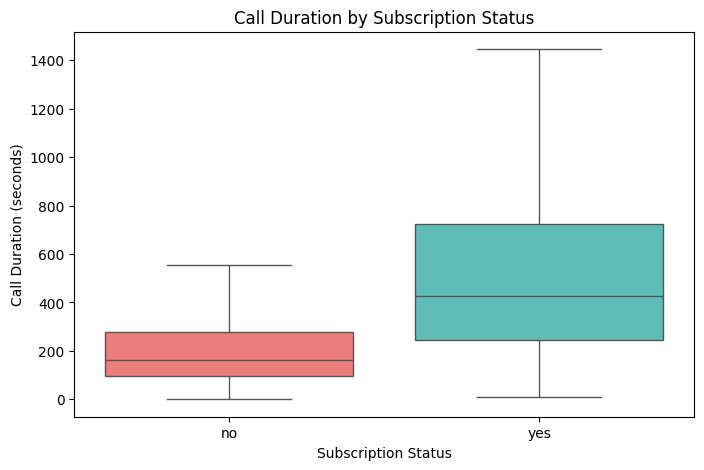

In [27]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="subscription", y="duration",
            order=["no", "yes"],
            palette=["#FF6B6B", "#4ECDC4"],
            hue="subscription", legend=False,
            showfliers=False)

plt.title("Call Duration by Subscription Status")
plt.xlabel("Subscription Status")
plt.ylabel("Call Duration (seconds)")
plt.show()

**Chart 7:** Were customers contacted in previous campaigns more likely to subscribe?

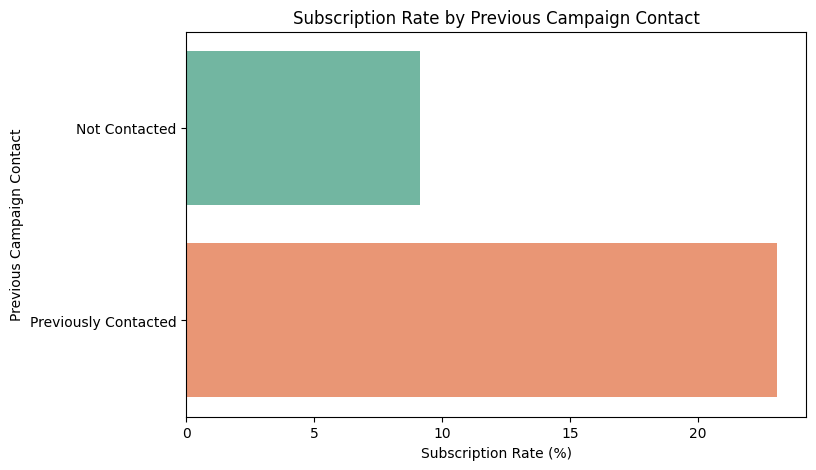

In [28]:
df["previous_contact"] = df["previous"].apply(
    lambda x: "Previously Contacted" if x > 0 else "Not Contacted"
)

df["subscribed"] = (df["subscription"] == "yes").astype(int) * 100

plt.figure(figsize=(8, 5))

sns.barplot(data=df, x="subscribed", y="previous_contact",
            hue="previous_contact", palette="Set2",
            legend=False, errorbar=None)

plt.title("Subscription Rate by Previous Campaign Contact")
plt.xlabel("Subscription Rate (%)")
plt.ylabel("Previous Campaign Contact")
plt.show()

**Syntax Explanation:**
1. df["previous"] – Selects the number of contacts made in previous campaigns.
2. .apply() – Applies a function to each value.
3. lambda x: – Checks whether the customer was previously contacted.
4. x > 0 – Indicates the customer was contacted at least once.
5. df["subscribed"] – Converts subscription status into percentages (0 or 100).
6. plt.figure(figsize=(8, 5)) – Sets the chart size.
7. sns.barplot() – Creates a horizontal bar chart.
8. x="subscribed" – Displays subscription rates on the X-axis.
9. y="previous_contact" – Displays previous contact categories on the Y-axis.
10. palette="Set2" – Applies different colours to the bars.
11. errorbar=None – Removes error bars.
12. plt.show() – Displays the chart.

**Result Explanation:**
1. The horizontal bar chart compares subscription rates between previously contacted and non-contacted customers.
2. The X-axis represents the subscription rate in percentage.
3. The Y-axis represents the previous campaign contact status.
4. Longer bars indicate higher subscription rates.
5. Shorter bars indicate lower subscription rates.
6. The chart helps identify whether customers contacted in previous campaigns have higher subscription rates.

**Project Conclusion:**
This analysis helps the bank understand the relationship between previous campaign contact history and term deposit subscriptions.

If previously contacted customers have higher subscription rates, they may be a useful group for future marketing campaigns.

**Note:** Previous contact history alone does not prove that repeated contact increases subscription success. Other factors, such as previous campaign outcomes, may influence customer responses.

**Chart 8:** Which previous campaign outcome leads to higher subscriptions?

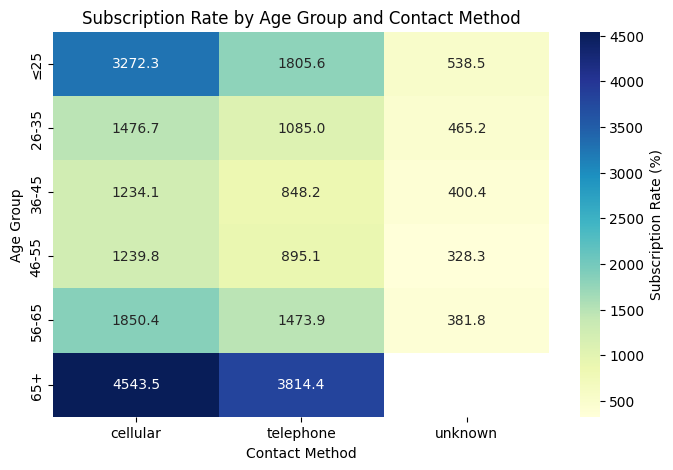

In [29]:
pivot = df.pivot_table(index="age_group",
                       columns="contact",
                       values="subscribed",
                       aggfunc="mean",
                       observed=True) * 100

plt.figure(figsize=(8, 5))

sns.heatmap(data=pivot, annot=True, fmt=".1f",
            cmap="YlGnBu",
            cbar_kws={"label": "Subscription Rate (%)"})

plt.title("Subscription Rate by Age Group and Contact Method")
plt.xlabel("Contact Method")
plt.ylabel("Age Group")
plt.show()


**Syntax Explanation:**
1. df.pivot_table() – Creates a summary table from the dataset.
2. index="age_group" – Displays age groups as rows.
3. columns="contact" – Displays contact methods as columns.
4. values="subscribed" – Selects the subscription column for calculation.
5. aggfunc="mean" – Calculates the average subscription value for each group.
6. observed=True – Includes only observed categorical groups.
7. * 100 – Converts the subscription rate into a percentage.
8. plt.figure(figsize=(8, 5)) – Sets the chart size.
9. sns.heatmap() – Creates a heatmap.
10. annot=True – Displays numerical values inside the cells.
11. fmt=".1f" – Displays values with one decimal place.
12. cmap="YlGnBu" – Applies a yellow, green and blue colour palette.
13. cbar_kws – Adds a label to the colour scale.
14. plt.title(), plt.xlabel(), plt.ylabel() – Add the chart title and axis labels.
15. plt.show() – Displays the heatmap.

**Result Explanation:**
1. The heatmap shows subscription rates across different age groups and contact methods.
2. The X-axis represents contact methods such as cellular and telephone.
3. The Y-axis represents customer age groups.
4. Each cell displays the subscription rate in percentage.
5. Darker colours indicate higher subscription rates.
6. Lighter colours indicate lower subscription rates.
7. The chart helps identify which combinations of age group and contact method have higher subscription rates.

**Project Conclusion:**
This analysis helps the bank understand how customer age groups and communication methods are associated with term deposit subscription rates.

By identifying combinations with higher subscription rates, the bank can improve customer segmentation and plan more targeted marketing campaigns.

**Important:** This code assumes subscribed contains 0 for no and 1 for yes. If your subscribed column already contains 0 and 100, remove * 100 from the pivot calculation to avoid incorrect percentages.

**Chart 9** Age vs Account Balance by Subscription – Scatter Plot

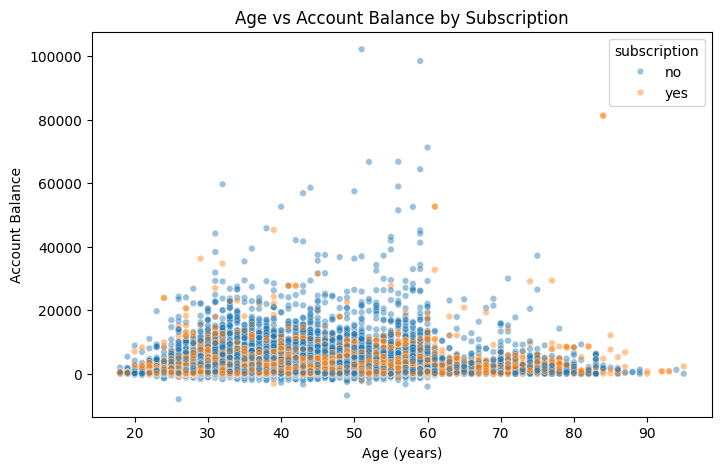

In [30]:
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x="age", y="balance",
                hue="subscription", alpha=0.45, s=22)

plt.title("Age vs Account Balance by Subscription")
plt.xlabel("Age (years)")
plt.ylabel("Account Balance")
plt.show()

**Syntax Explanation:**
1. plt.figure(figsize=(8, 5)) – Sets the chart size.
2. sns.scatterplot() – Creates a scatter plot.
3. data=sample – Uses the selected sample data.
4. x="age" – Displays customer age on the X-axis.
5. y="balance" – Displays account balance on the Y-axis.
6. hue="subscription" – Uses different colours for subscribed and non-subscribed customers.
7. alpha=0.45 – Makes the points slightly transparent.
8. s=22 – Sets the size of the points.
9. plt.title(), plt.xlabel(), plt.ylabel() – Add the chart title and axis labels.
10. plt.show() – Displays the scatter plot.

**Result Explanation:**
1. The scatter plot displays the relationship between customer age and account balance.
2. The X-axis represents customer age in years.
3. The Y-axis represents customer account balance.
4. Each point represents one customer.
5. Different colours indicate whether the customer subscribed (yes) or did not subscribe (no).
6. The chart helps identify possible patterns between age, account balance, and subscription status.

**Project Conclusion:**
The Age vs Account Balance analysis helps the bank understand how customer age and financial balance are associated with term deposit subscriptions.

This visualization can help identify customer segments for further analysis and support better marketing strategies.

**Note:** The scatter plot alone cannot confirm whether age or account balance significantly influences subscription success. Further statistical analysis is needed to establish stronger relationships.

**Chart 10:** Which Job Category Has the Highest Subscription Rate?

job
student          28.678038
retired          22.791519
unemployed       15.502686
management       13.755551
admin.           12.202669
self-employed    11.842939
unknown          11.805556
technician       11.056996
services          8.883004
housemaid         8.790323
entrepreneur      8.271688
blue-collar       7.274969
Name: subscription, dtype: float64


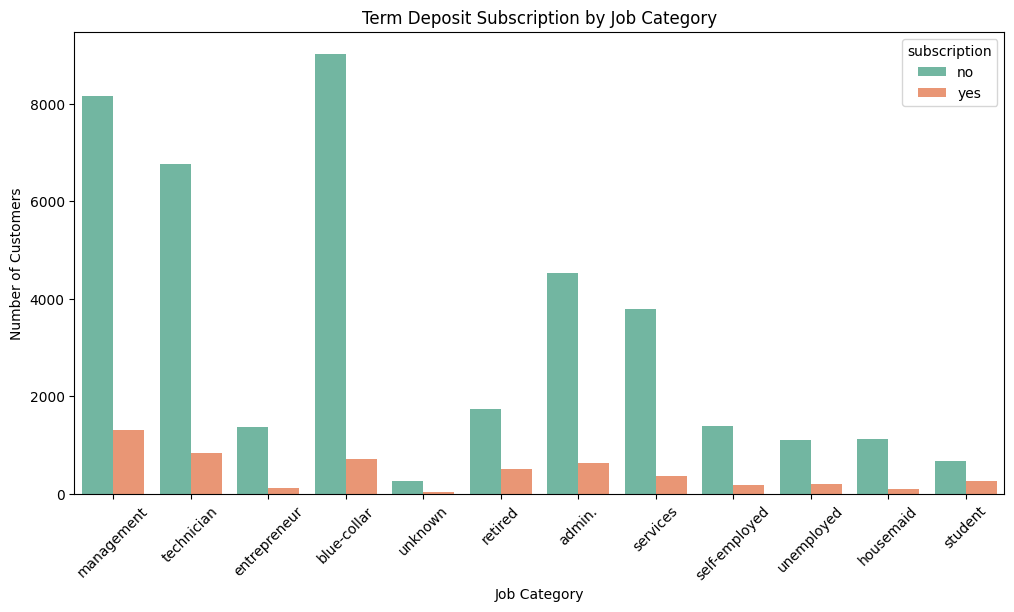

In [31]:
job_rate = df.groupby("job")["subscription"].apply(
    lambda x: (x == "yes").mean() * 100
).sort_values(ascending=False)

print(job_rate)
plt.figure(figsize=(12, 6))

sns.countplot(data=df, x="job", hue="subscription",
              palette="Set2")

plt.title("Term Deposit Subscription by Job Category")
plt.xlabel("Job Category")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45)
plt.show()

**Syntax Explanation:**
1. plt.figure(figsize=(12, 6)) – Sets the chart size.
2. sns.countplot() – Creates a grouped bar chart.
3. data=df – Uses the dataset.
4. x="job" – Displays different job categories.
5. hue="subscription" – Creates two bars for each job category (yes and no).
6. palette="Set2" – Applies different colours.
7. plt.xticks(rotation=45) – Rotates job category names for better readability.
8. plt.show() – Displays the chart.

**Result Explanation:**
1. The grouped bar chart compares subscribed and non-subscribed customers across job categories.
2. The X-axis represents job categories such as management, technician, blue-collar and services.
3. The Y-axis represents the number of customers.
4. Different colours represent subscription status (yes and no).
5. The chart helps identify which job categories have more successful subscriptions.

**Project Conclusion:**
This analysis helps the bank understand how term deposit subscription behaviour differs across job categories.

By identifying job categories with higher subscription rates, the bank can develop targeted marketing strategies and improve campaign effectiveness.

**Important:** The grouped count plot compares customer counts, not subscription rates. A job category with more subscribed customers may simply have more customers overall. Use the job_rate calculation to identify the category with the highest subscription percentage.

# **Downloading the cleaned Excel file**

In [32]:
df.to_excel("cleaned_bank_marketing.xlsx", index=False)

from google.colab import files

files.download("cleaned_bank_marketing.xlsx")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# **Dashboard**


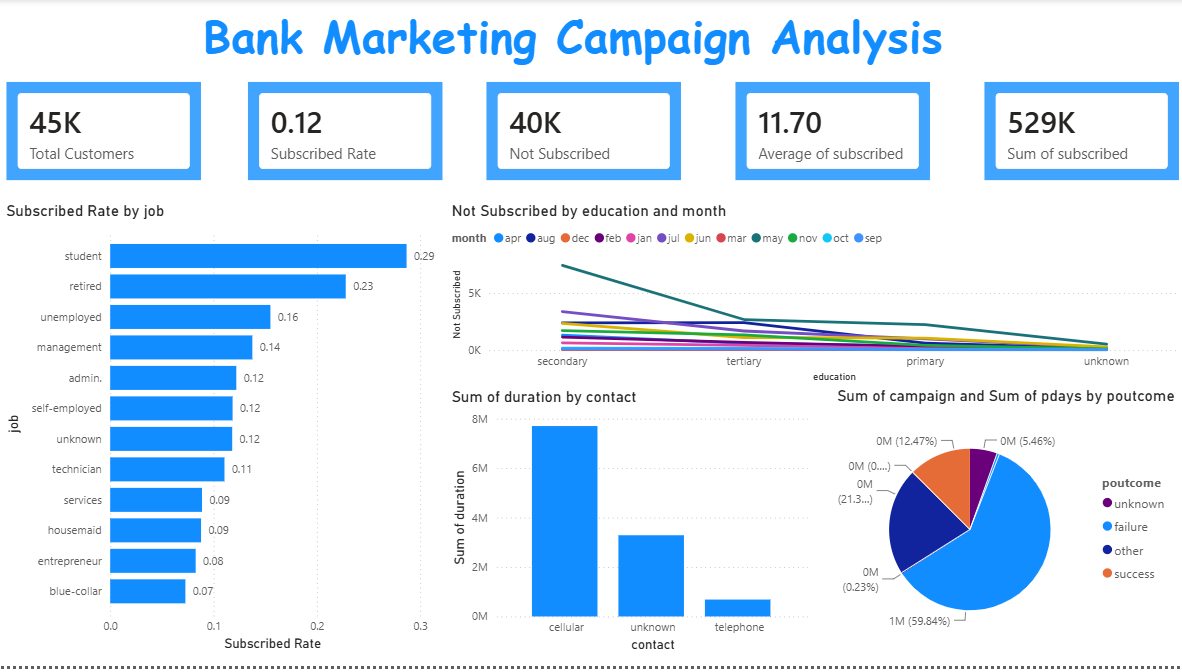

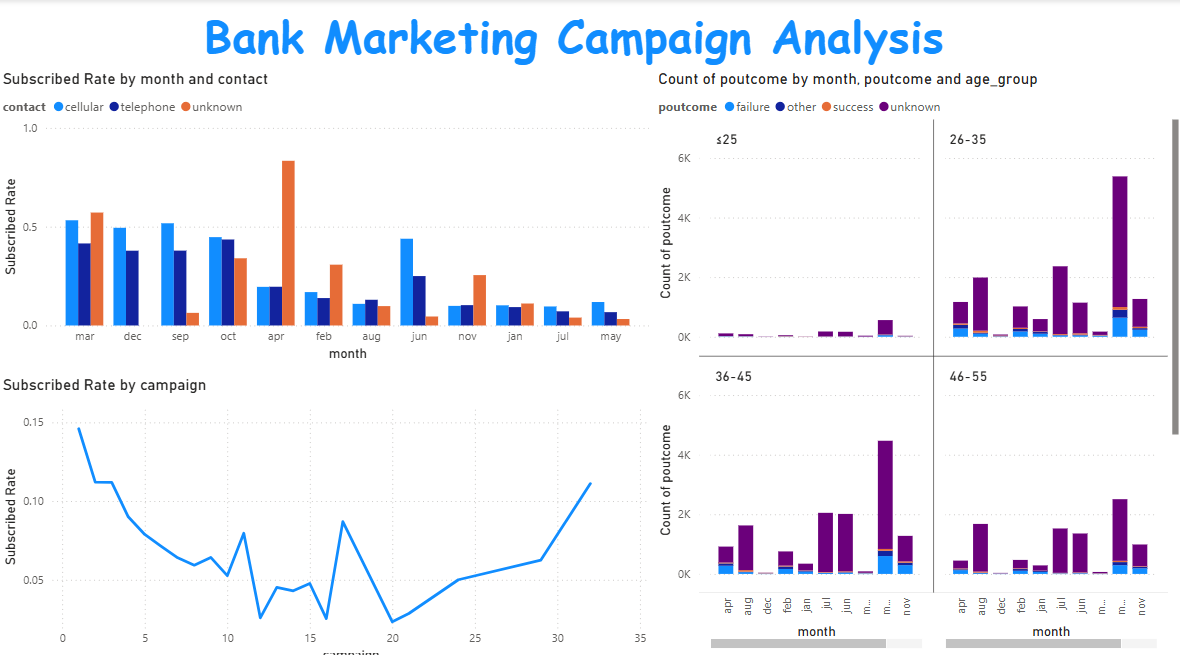

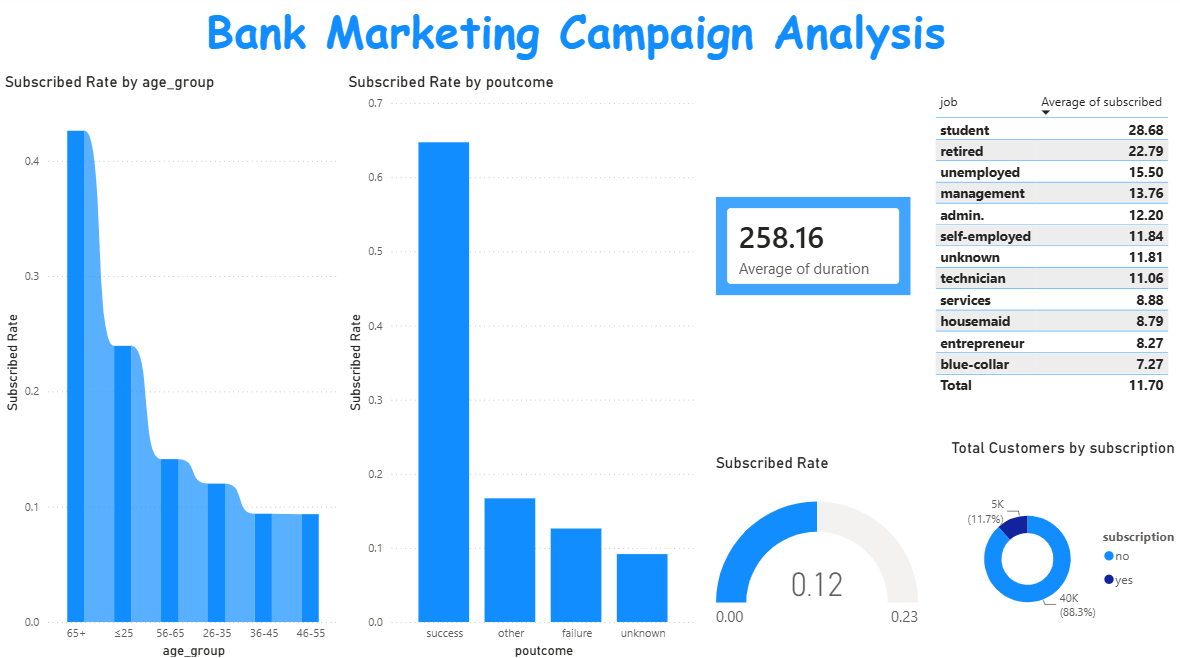

# **Conclusion:**

The Bank Marketing Campaign Analysis was conducted using Python to evaluate customer subscription patterns and the effectiveness of marketing campaigns.

The analysis covered 45,211 customer records, of which 5,289 customers subscribed to term deposits, resulting in an overall conversion rate of approximately 11.7%.

The job category analysis identified students and retired customers as the segments with the highest subscription rates. The project also explored customer age, financial balance, communication methods, contact frequency, call duration, and previous campaign history.

Data preprocessing identified no standard missing values or duplicate records, although unknown categorical values, skewed distributions and numerical outliers required attention.

Overall, the project demonstrates how data analytics can support customer segmentation and marketing decision-making. The bank can use these findings to develop targeted campaigns, evaluate contact strategies, and improve conversion performance.